In [19]:
import pandas as pd
import numpy as np
import nltk
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu
from rouge_score import rouge_scorer
import re
import os

# Download required NLTK data
nltk.download('punkt', quiet=True)

True

In [20]:
# Load the predictions CSV file
csv_filename = "/home/jovyan/Works/MSc_Thesis/mh_conversation/model_evaluation/results/ft-mental-chat16k-v1/mh_predictions_and_ground_truth.csv"

print("📊 Loading evaluation data from CSV...")
df = pd.read_csv(csv_filename)

print(f"✅ Loaded data with shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Extract data for evaluation
predictions = df['prediction'].tolist()
references = df['ground_truth'].tolist()
queries = df['query'].tolist()

print(f"🎯 Ready to evaluate {len(predictions)} predictions")

📊 Loading evaluation data from CSV...
✅ Loaded data with shape: (1606, 5)
📋 Columns: ['sample_id', 'query', 'ground_truth', 'prediction', 'instruction']
🎯 Ready to evaluate 1606 predictions


In [21]:
def calculate_bleu_scores(predictions, references):
    """Calculate BLEU scores for mental health conversations"""
    
    # Tokenize predictions and references
    pred_tokens = []
    ref_tokens = []
    
    for pred, ref in zip(predictions, references):
        # Handle NaN values - convert to empty string if NaN
        if pd.isna(pred):
            pred = ""
        if pd.isna(ref):
            ref = ""
            
        # Convert to string if not already
        pred = str(pred)
        ref = str(ref)
        
        # Clean and tokenize (preserve mental health specific terms)
        pred_clean = re.sub(r'[^\w\s\(\)\[\],\.!?;:]', '', pred.lower()).split()
        ref_clean = re.sub(r'[^\w\s\(\)\[\],\.!?;:]', '', ref.lower()).split()
        
        # Skip if either is empty after cleaning
        if not pred_clean or not ref_clean:
            pred_clean = ["<empty>"]  # Add placeholder token
            ref_clean = ["<empty>"]
        
        pred_tokens.append(pred_clean)
        ref_tokens.append([ref_clean])  # BLEU expects list of references
    
    # Calculate individual BLEU scores
    bleu_1_scores = []
    bleu_2_scores = []
    bleu_4_scores = []
    
    for pred, ref in zip(pred_tokens, ref_tokens):
        try:
            # Individual sentence BLEU scores
            bleu_1 = sentence_bleu(ref, pred, weights=(1, 0, 0, 0))
            bleu_2 = sentence_bleu(ref, pred, weights=(0.5, 0.5, 0, 0))
            bleu_4 = sentence_bleu(ref, pred, weights=(0.25, 0.25, 0.25, 0.25))
        except:
            # If BLEU calculation fails, assign 0
            bleu_1 = 0.0
            bleu_2 = 0.0
            bleu_4 = 0.0
        
        bleu_1_scores.append(bleu_1)
        bleu_2_scores.append(bleu_2)
        bleu_4_scores.append(bleu_4)
    
    # Corpus-level BLEU
    try:
        corpus_bleu_1 = corpus_bleu(ref_tokens, pred_tokens, weights=(1, 0, 0, 0))
        corpus_bleu_2 = corpus_bleu(ref_tokens, pred_tokens, weights=(0.5, 0.5, 0, 0))
        corpus_bleu_4 = corpus_bleu(ref_tokens, pred_tokens, weights=(0.25, 0.25, 0.25, 0.25))
    except:
        corpus_bleu_1 = 0.0
        corpus_bleu_2 = 0.0
        corpus_bleu_4 = 0.0
    
    return {
        'individual_bleu_1': bleu_1_scores,
        'individual_bleu_2': bleu_2_scores,
        'individual_bleu_4': bleu_4_scores,
        'corpus_bleu_1': corpus_bleu_1,
        'corpus_bleu_2': corpus_bleu_2,
        'corpus_bleu_4': corpus_bleu_4,
        'avg_bleu_1': sum(bleu_1_scores) / len(bleu_1_scores) if bleu_1_scores else 0.0,
        'avg_bleu_2': sum(bleu_2_scores) / len(bleu_2_scores) if bleu_2_scores else 0.0,
        'avg_bleu_4': sum(bleu_4_scores) / len(bleu_4_scores) if bleu_4_scores else 0.0
    }

print("✅ BLEU evaluation functions ready!")

✅ BLEU evaluation functions ready!


In [22]:
def calculate_rouge_scores(predictions, references):
    """Calculate ROUGE scores for mental health conversations"""
    
    # Initialize ROUGE scorer
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
    
    rouge1_scores = []
    rouge2_scores = []
    rougeL_scores = []
    
    for pred, ref in zip(predictions, references):
        # Handle NaN values
        if pd.isna(pred):
            pred = ""
        if pd.isna(ref):
            ref = ""
            
        # Convert to string if not already
        pred = str(pred)
        ref = str(ref)
        
        # Skip empty strings by assigning minimal score
        if not pred.strip() or not ref.strip():
            rouge1_scores.append(0.0)
            rouge2_scores.append(0.0)
            rougeL_scores.append(0.0)
            continue
        
        try:
            # Calculate ROUGE scores for this pair
            scores = scorer.score(ref, pred)
            
            # Extract F1 scores (most commonly reported)
            rouge1_scores.append(scores['rouge1'].fmeasure)
            rouge2_scores.append(scores['rouge2'].fmeasure)
            rougeL_scores.append(scores['rougeL'].fmeasure)
        except:
            # If ROUGE calculation fails, assign 0
            rouge1_scores.append(0.0)
            rouge2_scores.append(0.0)
            rougeL_scores.append(0.0)
    
    return {
        'rouge1_scores': rouge1_scores,
        'rouge2_scores': rouge2_scores,
        'rougeL_scores': rougeL_scores,
        'avg_rouge1': np.mean(rouge1_scores) if rouge1_scores else 0.0,
        'avg_rouge2': np.mean(rouge2_scores) if rouge2_scores else 0.0,
        'avg_rougeL': np.mean(rougeL_scores) if rougeL_scores else 0.0,
        'std_rouge1': np.std(rouge1_scores) if rouge1_scores else 0.0,
        'std_rouge2': np.std(rouge2_scores) if rouge2_scores else 0.0,
        'std_rougeL': np.std(rougeL_scores) if rougeL_scores else 0.0
    }

print("✅ ROUGE evaluation functions ready!")

✅ ROUGE evaluation functions ready!


In [23]:
# Calculate and display BLEU scores
print("📊 CALCULATING BLEU SCORES FOR MENTAL HEALTH CONVERSATIONS...")
print("="*70)

bleu_results = calculate_bleu_scores(predictions, references)

print("🎯 MENTAL HEALTH CONVERSATION BLEU RESULTS:")
print(f"   Corpus BLEU-1: {bleu_results['corpus_bleu_1']:.4f}")
print(f"   Corpus BLEU-2: {bleu_results['corpus_bleu_2']:.4f}")
print(f"   Corpus BLEU-4: {bleu_results['corpus_bleu_4']:.4f}")

print(f"\n📊 Average BLEU Scores:")
print(f"   Average BLEU-1: {bleu_results['avg_bleu_1']:.4f}")
print(f"   Average BLEU-2: {bleu_results['avg_bleu_2']:.4f}")
print(f"   Average BLEU-4: {bleu_results['avg_bleu_4']:.4f}")

print("="*70)

📊 CALCULATING BLEU SCORES FOR MENTAL HEALTH CONVERSATIONS...


/home/jovyan/Works/MSc_Thesis/mh_venv/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/home/jovyan/Works/MSc_Thesis/mh_venv/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/home/jovyan/Works/MSc_Thesis/mh_venv/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contain

🎯 MENTAL HEALTH CONVERSATION BLEU RESULTS:
   Corpus BLEU-1: 0.4466
   Corpus BLEU-2: 0.2652
   Corpus BLEU-4: 0.1220

📊 Average BLEU Scores:
   Average BLEU-1: 0.4181
   Average BLEU-2: 0.2463
   Average BLEU-4: 0.1104


In [24]:
# Calculate ROUGE scores
print("📊 CALCULATING ROUGE SCORES FOR MENTAL HEALTH CONVERSATIONS...")
print("="*70)

rouge_results = calculate_rouge_scores(predictions, references)

print("🎯 MENTAL HEALTH CONVERSATION ROUGE RESULTS:")
print(f"   ROUGE-1 (Unigram overlap): {rouge_results['avg_rouge1']:.4f} ± {rouge_results['std_rouge1']:.4f}")
print(f"   ROUGE-2 (Bigram overlap):  {rouge_results['avg_rouge2']:.4f} ± {rouge_results['std_rouge2']:.4f}")
print(f"   ROUGE-L (Longest sequence): {rouge_results['avg_rougeL']:.4f} ± {rouge_results['std_rougeL']:.4f}")

print("="*70)

📊 CALCULATING ROUGE SCORES FOR MENTAL HEALTH CONVERSATIONS...


🎯 MENTAL HEALTH CONVERSATION ROUGE RESULTS:
   ROUGE-1 (Unigram overlap): 0.5478 ± 0.1178
   ROUGE-2 (Bigram overlap):  0.2084 ± 0.0623
   ROUGE-L (Longest sequence): 0.2495 ± 0.0577


In [25]:
# Combined BLEU + ROUGE Analysis
print("🔍 COMBINED BLEU + ROUGE ANALYSIS:")
print("="*60)

bleu_4_scores = bleu_results['individual_bleu_4']

# Compare BLEU and ROUGE performance
print("📊 METRIC COMPARISON:")
print(f"   BLEU-4:  {bleu_results['avg_bleu_4']:.4f}")
print(f"   ROUGE-1: {rouge_results['avg_rouge1']:.4f}")
print(f"   ROUGE-2: {rouge_results['avg_rouge2']:.4f}")
print(f"   ROUGE-L: {rouge_results['avg_rougeL']:.4f}")

# Correlation analysis
correlation_r1_bleu = np.corrcoef(rouge_results['rouge1_scores'], bleu_4_scores)[0,1]
correlation_r2_bleu = np.corrcoef(rouge_results['rouge2_scores'], bleu_4_scores)[0,1]
correlation_rL_bleu = np.corrcoef(rouge_results['rougeL_scores'], bleu_4_scores)[0,1]

print(f"\n🔗 METRIC CORRELATIONS:")
print(f"   ROUGE-1 vs BLEU-4: {correlation_r1_bleu:.4f}")
print(f"   ROUGE-2 vs BLEU-4: {correlation_r2_bleu:.4f}")
print(f"   ROUGE-L vs BLEU-4: {correlation_rL_bleu:.4f}")

print("="*60)

🔍 COMBINED BLEU + ROUGE ANALYSIS:
📊 METRIC COMPARISON:
   BLEU-4:  0.1104
   ROUGE-1: 0.5478
   ROUGE-2: 0.2084
   ROUGE-L: 0.2495

🔗 METRIC CORRELATIONS:
   ROUGE-1 vs BLEU-4: 0.7630
   ROUGE-2 vs BLEU-4: 0.9232
   ROUGE-L vs BLEU-4: 0.8536


In [26]:
# Performance categorization
print("🏆 PERFORMANCE CATEGORIZATION:")
print("="*50)

def categorize_performance(scores, metric_name, thresholds):
    excellent = [s for s in scores if s >= thresholds[0]]
    good = [s for s in scores if thresholds[1] <= s < thresholds[0]]
    fair = [s for s in scores if thresholds[2] <= s < thresholds[1]]
    poor = [s for s in scores if s < thresholds[2]]
    
    total = len(scores)
    print(f"\n{metric_name} Categories:")
    print(f"   Excellent (≥{thresholds[0]}): {len(excellent)}/{total} ({len(excellent)/total*100:.1f}%)")
    print(f"   Good ({thresholds[1]}-{thresholds[0]}): {len(good)}/{total} ({len(good)/total*100:.1f}%)")
    print(f"   Fair ({thresholds[2]}-{thresholds[1]}): {len(fair)}/{total} ({len(fair)/total*100:.1f}%)")
    print(f"   Poor (<{thresholds[2]}): {len(poor)}/{total} ({len(poor)/total*100:.1f}%)")

# BLEU categorization
categorize_performance(bleu_4_scores, "BLEU-4", [0.4, 0.2, 0.1])

# ROUGE categorization
categorize_performance(rouge_results['rouge1_scores'], "ROUGE-1", [0.6, 0.4, 0.2])
categorize_performance(rouge_results['rouge2_scores'], "ROUGE-2", [0.6, 0.4, 0.2])
categorize_performance(rouge_results['rougeL_scores'], "ROUGE-L", [0.6, 0.4, 0.2])

print("="*50)

🏆 PERFORMANCE CATEGORIZATION:

BLEU-4 Categories:
   Excellent (≥0.4): 0/1606 (0.0%)
   Good (0.2-0.4): 87/1606 (5.4%)
   Fair (0.1-0.2): 828/1606 (51.6%)
   Poor (<0.1): 691/1606 (43.0%)

ROUGE-1 Categories:
   Excellent (≥0.6): 685/1606 (42.7%)
   Good (0.4-0.6): 726/1606 (45.2%)
   Fair (0.2-0.4): 162/1606 (10.1%)
   Poor (<0.2): 33/1606 (2.1%)

ROUGE-2 Categories:
   Excellent (≥0.6): 0/1606 (0.0%)
   Good (0.4-0.6): 7/1606 (0.4%)
   Fair (0.2-0.4): 916/1606 (57.0%)
   Poor (<0.2): 683/1606 (42.5%)

ROUGE-L Categories:
   Excellent (≥0.6): 0/1606 (0.0%)
   Good (0.4-0.6): 23/1606 (1.4%)
   Fair (0.2-0.4): 1355/1606 (84.4%)
   Poor (<0.2): 228/1606 (14.2%)


In [27]:
# Best and worst samples analysis
print("🔍 DETAILED SAMPLE ANALYSIS:")
print("="*70)

# Find samples with highest and lowest combined scores
combined_scores = []
for i in range(len(bleu_4_scores)):
    combined = (bleu_4_scores[i] * 0.3 + 
                rouge_results['rouge1_scores'][i] * 0.25 + 
                rouge_results['rouge2_scores'][i] * 0.25 + 
                rouge_results['rougeL_scores'][i] * 0.2)
    combined_scores.append(combined)

best_idx = combined_scores.index(max(combined_scores))
worst_idx = combined_scores.index(min(combined_scores))

print(f"🏆 BEST PERFORMING SAMPLE (Combined Score: {max(combined_scores):.4f}):")
print(f"   BLEU-4: {bleu_4_scores[best_idx]:.4f}")
print(f"   ROUGE-1: {rouge_results['rouge1_scores'][best_idx]:.4f}")
print(f"   ROUGE-2: {rouge_results['rouge2_scores'][best_idx]:.4f}")
print(f"   ROUGE-L: {rouge_results['rougeL_scores'][best_idx]:.4f}")
print(f"\nQuery: {queries[best_idx]}")
print(f"\nGround Truth: {references[best_idx][:200]}...")
print(f"\nPrediction: {predictions[best_idx][:200]}...")

print(f"\n⚠️ WORST PERFORMING SAMPLE (Combined Score: {min(combined_scores):.4f}):")
print(f"   BLEU-4: {bleu_4_scores[worst_idx]:.4f}")
print(f"   ROUGE-1: {rouge_results['rouge1_scores'][worst_idx]:.4f}")
print(f"   ROUGE-2: {rouge_results['rouge2_scores'][worst_idx]:.4f}")
print(f"   ROUGE-L: {rouge_results['rougeL_scores'][worst_idx]:.4f}")
print(f"\nQuery: {queries[worst_idx]}")
print(f"\nGround Truth: {references[worst_idx][:200]}...")
# print(f"\nPrediction: {predictions[worst_idx][:200]}...")

print("="*70)

🔍 DETAILED SAMPLE ANALYSIS:
🏆 BEST PERFORMING SAMPLE (Combined Score: 0.5085):
   BLEU-4: 0.3579
   ROUGE-1: 0.7549
   ROUGE-2: 0.4610
   ROUGE-L: 0.4855

Query: Lately, I have been experiencing persistent feelings of sadness, hopelessness, and a lack of interest in activities that used to bring joy. My goal in counseling is to understand the underlying causes of my depression and learn coping mechanisms to improve my mood and overall well-being.

The onset of my depressive symptoms coincides with a recent job loss. The financial strain, coupled with prolonged isolation due to the pandemic, has intensified my feelings of despair and contributed to a general sense of emptiness.

Specific situations triggering my depressed mood include difficulty getting out of bed, withdrawing from social interactions, and losing motivation in pursuing personal goals or hobbies. These events exacerbate my negative emotions and make daily functioning challenging.

Symptoms associated with my depression i

In [28]:
# Save detailed evaluation results
output_dir = "/home/jovyan/Works/MSc_Thesis/mh_conversation/model_evaluation/results"

# Create results dataframe
results_df = df.copy()
results_df['bleu_1'] = bleu_results['individual_bleu_1']
results_df['bleu_2'] = bleu_results['individual_bleu_2']
results_df['bleu_4'] = bleu_results['individual_bleu_4']
results_df['rouge_1'] = rouge_results['rouge1_scores']
results_df['rouge_2'] = rouge_results['rouge2_scores']
results_df['rouge_L'] = rouge_results['rougeL_scores']
results_df['combined_score'] = combined_scores

# Save detailed results
detailed_results_file = f"{output_dir}/detailed_evaluation_results.csv"
results_df.to_csv(detailed_results_file, index=False)

# Save summary statistics
summary_stats = {
    'metric': ['BLEU-1', 'BLEU-2', 'BLEU-4', 'ROUGE-1', 'ROUGE-2', 'ROUGE-L'],
    'mean': [
        bleu_results['avg_bleu_1'], bleu_results['avg_bleu_2'], bleu_results['avg_bleu_4'],
        rouge_results['avg_rouge1'], rouge_results['avg_rouge2'], rouge_results['avg_rougeL']
    ],
    'std': [
        np.std(bleu_results['individual_bleu_1']), np.std(bleu_results['individual_bleu_2']), np.std(bleu_results['individual_bleu_4']),
        rouge_results['std_rouge1'], rouge_results['std_rouge2'], rouge_results['std_rougeL']
    ]
}

summary_df = pd.DataFrame(summary_stats)
summary_file = f"{output_dir}/evaluation_summary.csv"
summary_df.to_csv(summary_file, index=False)

print(f"✅ Saved detailed results to: {detailed_results_file}")
print(f"✅ Saved summary statistics to: {summary_file}")
print("🎉 Evaluation complete!")

✅ Saved detailed results to: /home/jovyan/Works/MSc_Thesis/mh_conversation/model_evaluation/results/detailed_evaluation_results.csv
✅ Saved summary statistics to: /home/jovyan/Works/MSc_Thesis/mh_conversation/model_evaluation/results/evaluation_summary.csv
🎉 Evaluation complete!


In [29]:
# Additional imports for semantic similarity
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

print("✅ Semantic similarity imports ready!")

✅ Semantic similarity imports ready!


In [41]:
# Load pre-trained sentence transformer model for semantic similarity
print("🤖 Loading semantic similarity model...")

# Using a model specifically good for mental health/clinical text
# You can also try: 'all-MiniLM-L6-v2', 'all-mpnet-base-v2', or 'clinical-bert'
semantic_model = SentenceTransformer('all-MiniLM-L6-v2')

print("✅ Semantic similarity model loaded!")

🤖 Loading semantic similarity model...
✅ Semantic similarity model loaded!


In [31]:
def calculate_semantic_similarity(predictions, references, model, batch_size=32):
    """Calculate semantic similarity scores using sentence transformers"""
    
    # Clean and prepare texts
    clean_predictions = []
    clean_references = []
    
    for pred, ref in zip(predictions, references):
        # Handle NaN values
        if pd.isna(pred):
            pred = ""
        if pd.isna(ref):
            ref = ""
            
        # Convert to string and clean
        pred = str(pred).strip()
        ref = str(ref).strip()
        
        # Handle empty strings
        if not pred:
            pred = "No response provided"
        if not ref:
            ref = "No reference available"
            
        clean_predictions.append(pred)
        clean_references.append(ref)
    
    print(f"🔄 Computing embeddings for {len(clean_predictions)} text pairs...")
    
    # Compute embeddings in batches for memory efficiency
    pred_embeddings = model.encode(clean_predictions, batch_size=batch_size, show_progress_bar=True)
    ref_embeddings = model.encode(clean_references, batch_size=batch_size, show_progress_bar=True)
    
    # Calculate cosine similarities
    similarities = []
    for pred_emb, ref_emb in zip(pred_embeddings, ref_embeddings):
        similarity = cosine_similarity([pred_emb], [ref_emb])[0][0]
        similarities.append(similarity)
    
    return {
        'similarities': similarities,
        'mean_similarity': np.mean(similarities),
        'std_similarity': np.std(similarities),
        'median_similarity': np.median(similarities),
        'min_similarity': np.min(similarities),
        'max_similarity': np.max(similarities)
    }

print("✅ Semantic similarity function ready!")

✅ Semantic similarity function ready!


In [32]:
# Calculate semantic similarity scores
print("📊 CALCULATING SEMANTIC SIMILARITY FOR MENTAL HEALTH CONVERSATIONS...")
print("="*70)

semantic_results = calculate_semantic_similarity(predictions, references, semantic_model)

print("🎯 MENTAL HEALTH CONVERSATION SEMANTIC SIMILARITY RESULTS:")
print(f"   Mean Cosine Similarity: {semantic_results['mean_similarity']:.4f} ± {semantic_results['std_similarity']:.4f}")
print(f"   Median Similarity: {semantic_results['median_similarity']:.4f}")
print(f"   Min Similarity: {semantic_results['min_similarity']:.4f}")
print(f"   Max Similarity: {semantic_results['max_similarity']:.4f}")

print("="*70)

📊 CALCULATING SEMANTIC SIMILARITY FOR MENTAL HEALTH CONVERSATIONS...
🔄 Computing embeddings for 1606 text pairs...


Batches:   0%|          | 0/51 [00:00<?, ?it/s]

Batches: 100%|██████████| 51/51 [00:01<00:00, 42.61it/s]


🎯 MENTAL HEALTH CONVERSATION SEMANTIC SIMILARITY RESULTS:
   Mean Cosine Similarity: 0.8101 ± 0.1007
   Median Similarity: 0.8366
   Min Similarity: 0.0110
   Max Similarity: 0.9729


In [33]:
# Semantic similarity distribution analysis
print("📊 SEMANTIC SIMILARITY DISTRIBUTION ANALYSIS:")
print("="*60)

similarities = semantic_results['similarities']

# Categorize semantic similarity scores
def categorize_semantic_similarity(scores, metric_name, thresholds):
    excellent = [s for s in scores if s >= thresholds[0]]  # Very similar
    good = [s for s in scores if thresholds[1] <= s < thresholds[0]]  # Similar
    fair = [s for s in scores if thresholds[2] <= s < thresholds[1]]  # Somewhat similar
    poor = [s for s in scores if s < thresholds[2]]  # Different
    
    total = len(scores)
    print(f"\n{metric_name} Categories:")
    print(f"   Excellent (≥{thresholds[0]}): {len(excellent)}/{total} ({len(excellent)/total*100:.1f}%)")
    print(f"   Good ({thresholds[1]}-{thresholds[0]}): {len(good)}/{total} ({len(good)/total*100:.1f}%)")
    print(f"   Fair ({thresholds[2]}-{thresholds[1]}): {len(fair)}/{total} ({len(fair)/total*100:.1f}%)")
    print(f"   Poor (<{thresholds[2]}): {len(poor)}/{total} ({len(poor)/total*100:.1f}%)")

# Semantic similarity thresholds (cosine similarity ranges 0-1)
categorize_semantic_similarity(similarities, "Semantic Similarity", [0.8, 0.6, 0.4])

print("="*60)

📊 SEMANTIC SIMILARITY DISTRIBUTION ANALYSIS:

Semantic Similarity Categories:
   Excellent (≥0.8): 1057/1606 (65.8%)
   Good (0.6-0.8): 475/1606 (29.6%)
   Fair (0.4-0.6): 67/1606 (4.2%)
   Poor (<0.4): 7/1606 (0.4%)


In [34]:
# Correlation analysis between semantic similarity and other metrics
print("🔗 CORRELATION ANALYSIS: SEMANTIC SIMILARITY vs OTHER METRICS:")
print("="*70)

# Calculate correlations
bleu_4_scores = bleu_results['individual_bleu_4']
similarities = semantic_results['similarities']

corr_semantic_bleu4 = np.corrcoef(similarities, bleu_4_scores)[0,1]
corr_semantic_rouge1 = np.corrcoef(similarities, rouge_results['rouge1_scores'])[0,1]
corr_semantic_rouge2 = np.corrcoef(similarities, rouge_results['rouge2_scores'])[0,1]
corr_semantic_rougeL = np.corrcoef(similarities, rouge_results['rougeL_scores'])[0,1]

print("🔗 CORRELATION COEFFICIENTS:")
print(f"   Semantic Similarity vs BLEU-4:  {corr_semantic_bleu4:.4f}")
print(f"   Semantic Similarity vs ROUGE-1: {corr_semantic_rouge1:.4f}")
print(f"   Semantic Similarity vs ROUGE-2: {corr_semantic_rouge2:.4f}")
print(f"   Semantic Similarity vs ROUGE-L: {corr_semantic_rougeL:.4f}")

print(f"\n📊 ENHANCED METRIC COMPARISON:")
print(f"   BLEU-4:             {bleu_results['avg_bleu_4']:.4f}")
print(f"   ROUGE-1:            {rouge_results['avg_rouge1']:.4f}")
print(f"   ROUGE-2:            {rouge_results['avg_rouge2']:.4f}")
print(f"   ROUGE-L:            {rouge_results['avg_rougeL']:.4f}")
print(f"   Semantic Similarity: {semantic_results['mean_similarity']:.4f}")

print("="*70)

🔗 CORRELATION ANALYSIS: SEMANTIC SIMILARITY vs OTHER METRICS:
🔗 CORRELATION COEFFICIENTS:
   Semantic Similarity vs BLEU-4:  0.5053
   Semantic Similarity vs ROUGE-1: 0.5880
   Semantic Similarity vs ROUGE-2: 0.5469
   Semantic Similarity vs ROUGE-L: 0.4826

📊 ENHANCED METRIC COMPARISON:
   BLEU-4:             0.1104
   ROUGE-1:            0.5478
   ROUGE-2:            0.2084
   ROUGE-L:            0.2495
   Semantic Similarity: 0.8101


In [35]:
# Enhanced combined score including semantic similarity
print("🎯 ENHANCED COMBINED SCORE WITH SEMANTIC SIMILARITY:")
print("="*70)

# Calculate enhanced combined scores with semantic similarity
enhanced_combined_scores = []
for i in range(len(bleu_4_scores)):
    # Weight: semantic similarity gets higher weight for mental health conversations
    enhanced_combined = (
        bleu_4_scores[i] * 0.2 +                          # BLEU-4: 20%
        rouge_results['rouge1_scores'][i] * 0.2 +          # ROUGE-1: 20%
        rouge_results['rouge2_scores'][i] * 0.15 +         # ROUGE-2: 15%
        rouge_results['rougeL_scores'][i] * 0.15 +         # ROUGE-L: 15%
        similarities[i] * 0.3                              # Semantic: 30%
    )
    enhanced_combined_scores.append(enhanced_combined)

# Find best and worst samples with enhanced scoring
best_enhanced_idx = enhanced_combined_scores.index(max(enhanced_combined_scores))
worst_enhanced_idx = enhanced_combined_scores.index(min(enhanced_combined_scores))

print(f"🏆 BEST SAMPLE (Enhanced Score: {max(enhanced_combined_scores):.4f}):")
print(f"   BLEU-4: {bleu_4_scores[best_enhanced_idx]:.4f}")
print(f"   ROUGE-1: {rouge_results['rouge1_scores'][best_enhanced_idx]:.4f}")
print(f"   ROUGE-2: {rouge_results['rouge2_scores'][best_enhanced_idx]:.4f}")
print(f"   ROUGE-L: {rouge_results['rougeL_scores'][best_enhanced_idx]:.4f}")
print(f"   Semantic: {similarities[best_enhanced_idx]:.4f}")

print(f"\n⚠️ WORST SAMPLE (Enhanced Score: {min(enhanced_combined_scores):.4f}):")
print(f"   BLEU-4: {bleu_4_scores[worst_enhanced_idx]:.4f}")
print(f"   ROUGE-1: {rouge_results['rouge1_scores'][worst_enhanced_idx]:.4f}")
print(f"   ROUGE-2: {rouge_results['rouge2_scores'][worst_enhanced_idx]:.4f}")
print(f"   ROUGE-L: {rouge_results['rougeL_scores'][worst_enhanced_idx]:.4f}")
print(f"   Semantic: {similarities[worst_enhanced_idx]:.4f}")

print("="*70)

🎯 ENHANCED COMBINED SCORE WITH SEMANTIC SIMILARITY:
🏆 BEST SAMPLE (Enhanced Score: 0.6470):
   BLEU-4: 0.3579
   ROUGE-1: 0.7549
   ROUGE-2: 0.4610
   ROUGE-L: 0.4855
   Semantic: 0.9416

⚠️ WORST SAMPLE (Enhanced Score: 0.0033):
   BLEU-4: 0.0000
   ROUGE-1: 0.0000
   ROUGE-2: 0.0000
   ROUGE-L: 0.0000
   Semantic: 0.0110


📊 Creating evaluation metrics visualization...


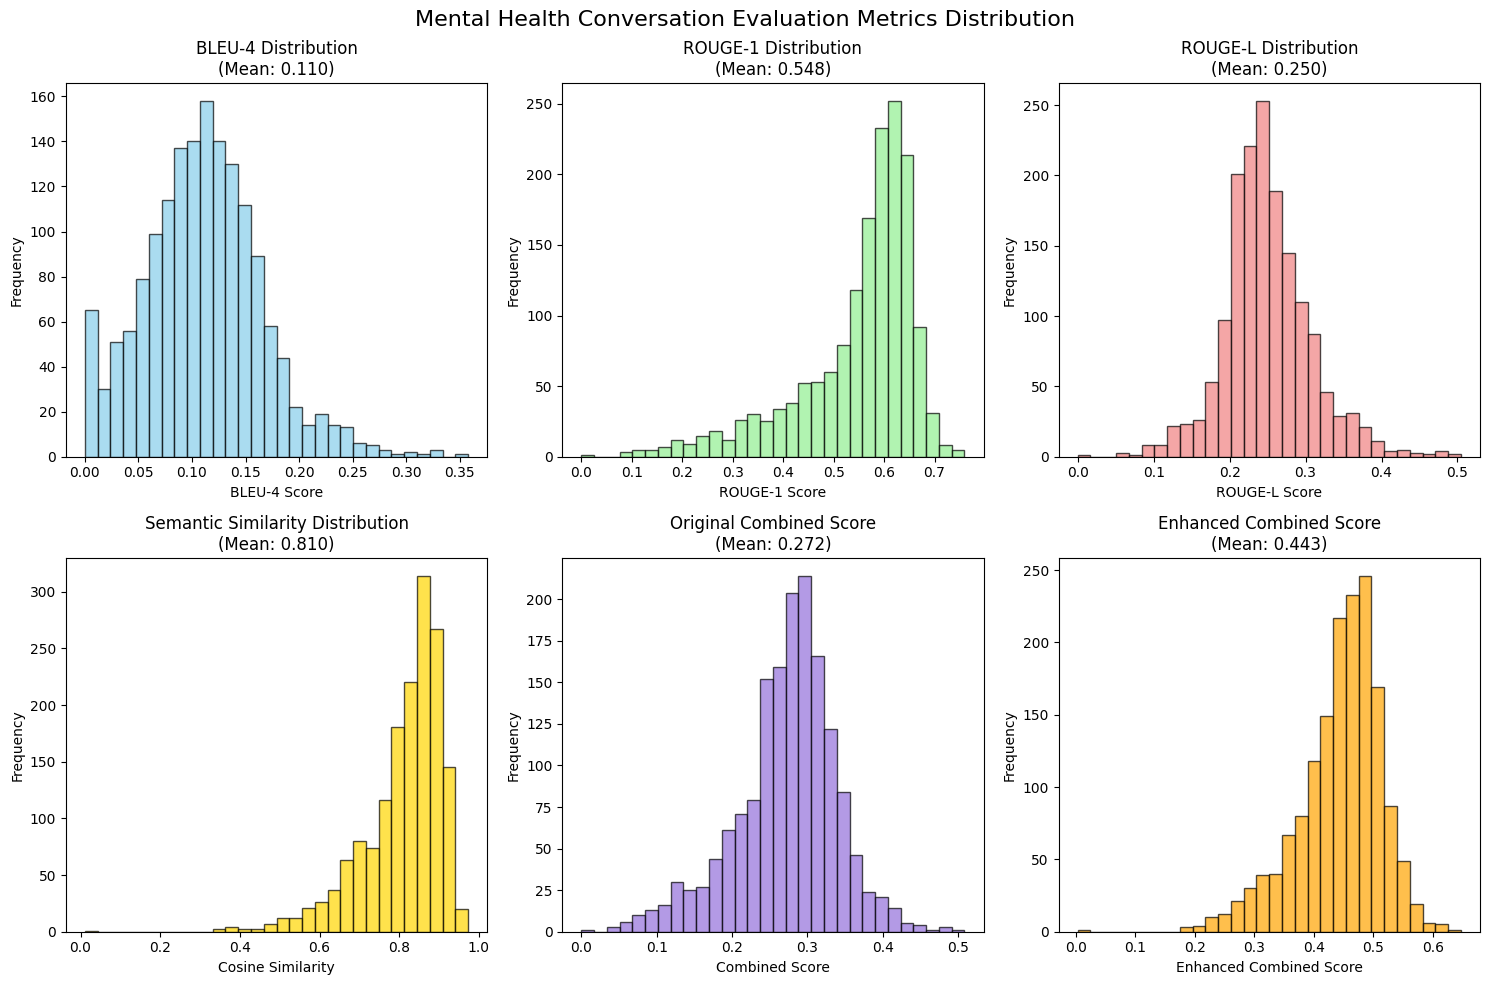

✅ Visualization saved!


In [36]:
# Create visualization of metric distributions
print("📊 Creating evaluation metrics visualization...")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Mental Health Conversation Evaluation Metrics Distribution', fontsize=16)

# BLEU-4 distribution
axes[0,0].hist(bleu_4_scores, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
axes[0,0].set_title(f'BLEU-4 Distribution\n(Mean: {bleu_results["avg_bleu_4"]:.3f})')
axes[0,0].set_xlabel('BLEU-4 Score')
axes[0,0].set_ylabel('Frequency')

# ROUGE-1 distribution
axes[0,1].hist(rouge_results['rouge1_scores'], bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
axes[0,1].set_title(f'ROUGE-1 Distribution\n(Mean: {rouge_results["avg_rouge1"]:.3f})')
axes[0,1].set_xlabel('ROUGE-1 Score')
axes[0,1].set_ylabel('Frequency')

# ROUGE-L distribution
axes[0,2].hist(rouge_results['rougeL_scores'], bins=30, alpha=0.7, color='lightcoral', edgecolor='black')
axes[0,2].set_title(f'ROUGE-L Distribution\n(Mean: {rouge_results["avg_rougeL"]:.3f})')
axes[0,2].set_xlabel('ROUGE-L Score')
axes[0,2].set_ylabel('Frequency')

# Semantic similarity distribution
axes[1,0].hist(similarities, bins=30, alpha=0.7, color='gold', edgecolor='black')
axes[1,0].set_title(f'Semantic Similarity Distribution\n(Mean: {semantic_results["mean_similarity"]:.3f})')
axes[1,0].set_xlabel('Cosine Similarity')
axes[1,0].set_ylabel('Frequency')

# Original combined score distribution
axes[1,1].hist(combined_scores, bins=30, alpha=0.7, color='mediumpurple', edgecolor='black')
axes[1,1].set_title(f'Original Combined Score\n(Mean: {np.mean(combined_scores):.3f})')
axes[1,1].set_xlabel('Combined Score')
axes[1,1].set_ylabel('Frequency')

# Enhanced combined score distribution
axes[1,2].hist(enhanced_combined_scores, bins=30, alpha=0.7, color='orange', edgecolor='black')
axes[1,2].set_title(f'Enhanced Combined Score\n(Mean: {np.mean(enhanced_combined_scores):.3f})')
axes[1,2].set_xlabel('Enhanced Combined Score')
axes[1,2].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig(f"{output_dir}/evaluation_metrics_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Visualization saved!")

In [37]:
# Save detailed evaluation results with semantic similarity
output_dir = "/home/jovyan/Works/MSc_Thesis/mh_conversation/model_evaluation/results/ft-mental-chat16k-v1"

# Create enhanced results dataframe
results_df = df.copy()
results_df['bleu_1'] = bleu_results['individual_bleu_1']
results_df['bleu_2'] = bleu_results['individual_bleu_2']
results_df['bleu_4'] = bleu_results['individual_bleu_4']
results_df['rouge_1'] = rouge_results['rouge1_scores']
results_df['rouge_2'] = rouge_results['rouge2_scores']
results_df['rouge_L'] = rouge_results['rougeL_scores']
results_df['semantic_similarity'] = similarities
results_df['combined_score'] = combined_scores
results_df['enhanced_combined_score'] = enhanced_combined_scores

# Save detailed results
detailed_results_file = f"{output_dir}/detailed_evaluation_results_with_semantic.csv"
results_df.to_csv(detailed_results_file, index=False)

# Enhanced summary statistics
summary_stats = {
    'metric': ['BLEU-1', 'BLEU-2', 'BLEU-4', 'ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'Semantic-Similarity'],
    'mean': [
        bleu_results['avg_bleu_1'], bleu_results['avg_bleu_2'], bleu_results['avg_bleu_4'],
        rouge_results['avg_rouge1'], rouge_results['avg_rouge2'], rouge_results['avg_rougeL'],
        semantic_results['mean_similarity']
    ],
    'std': [
        np.std(bleu_results['individual_bleu_1']), np.std(bleu_results['individual_bleu_2']), np.std(bleu_results['individual_bleu_4']),
        rouge_results['std_rouge1'], rouge_results['std_rouge2'], rouge_results['std_rougeL'],
        semantic_results['std_similarity']
    ]
}

summary_df = pd.DataFrame(summary_stats)
summary_file = f"{output_dir}/evaluation_summary_with_semantic.csv"
summary_df.to_csv(summary_file, index=False)

print(f"✅ Saved enhanced results to: {detailed_results_file}")
print(f"✅ Saved enhanced summary to: {summary_file}")
print("🎉 Enhanced evaluation with semantic similarity complete!")

✅ Saved enhanced results to: /home/jovyan/Works/MSc_Thesis/mh_conversation/model_evaluation/results/ft-mental-chat16k-v1/detailed_evaluation_results_with_semantic.csv
✅ Saved enhanced summary to: /home/jovyan/Works/MSc_Thesis/mh_conversation/model_evaluation/results/ft-mental-chat16k-v1/evaluation_summary_with_semantic.csv
🎉 Enhanced evaluation with semantic similarity complete!
